# Optimal Portfolio Construction, Style Attribution, and Asset Allocation

## An Empirical Evaluation of Mean-Variance Optimization, Factor Models, and the Black-Litterman Framework

### Import libraries

In [101]:
import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.robust as robust
import io
import requests
import zipfile
import seaborn as sns

### Phase 1: Data Acquisition & Preprocessing

#### Data Retrieval

In [102]:
tickers = ['AMZN', 'MSFT', 'JPM', 'JNJ', 'V', 'UNH', 'PG', 'HD', 'XOM', 'NVDA']
start_date = '2023-09-01'
end_date = '2025-12-31'

# Explicitly set auto_adjust=False to guarantee the 'Adj Close' column is returned
data = yf.download(tickers, start=start_date, end=end_date, interval='1d', auto_adjust=False)

# Safely extract 'Adj Close' across different yfinance/pandas multi-index versions
if isinstance(data.columns, pd.MultiIndex):
    adj_close = data['Adj Close']
else:
    adj_close = data['Adj Close']

# Optional: Resample to weekly data (Friday closes)
weekly_data = adj_close.resample('W-FRI').last()

print(adj_close.head())

[*********************100%***********************]  10 of 10 completed

Ticker            AMZN          HD         JNJ         JPM        MSFT  \
Date                                                                     
2023-09-01  138.119995  310.669708  147.365677  137.442947  321.138458   
2023-09-05  137.270004  305.726318  147.549316  135.926407  325.916443   
2023-09-06  135.360001  304.066010  145.097488  135.701721  325.261902   
2023-09-07  137.850006  306.323212  146.952408  134.540924  322.359833   
2023-09-08  138.229996  306.593719  147.439117  134.643890  326.619995   

Ticker           NVDA          PG         UNH           V         XOM  
Date                                                                   
2023-09-01  48.414680  142.777161  448.239441  242.515732  102.866066  
2023-09-05  48.453606  140.864365  452.540802  239.808182  102.875122  
2023-09-06  46.973370  140.587112  448.898376  240.609665  103.763153  
2023-09-07  46.154892  141.927032  456.305603  241.567581  103.255714  
2023-09-08  45.487144  141.317169  454.264648  24

#### Factor Data & Risk-Free Rate

In [103]:
import pandas_datareader.data as web

# Define estimation window
start_date = '2023-09-01'
end_date = '2025-12-31'

# Fetch Fama-French 5 Factors (Daily) from Kenneth French's Data Library
# Note: Use '_daily' suffix for daily frequency data
ff_5_factors_daily = web.DataReader(
    'F-F_Research_Data_5_Factors_2x3_daily',
    'famafrench',
    start=start_date,
    end=end_date
)[0]

# Optional: If monthly aggregation is preferred over daily data
ff_5_factors_monthly = web.DataReader(
    'F-F_Research_Data_5_Factors_2x3',
    'famafrench',
    start=start_date,
    end=end_date
)[0]

# Scale factors from percentage points to decimals
ff_5_factors_daily = ff_5_factors_daily / 100.0
print(ff_5_factors_daily.head())

            Mkt-RF     SMB     HML     RMW     CMA      RF
Date                                                      
2023-09-01  0.0026  0.0085  0.0058  0.0000 -0.0021  0.0002
2023-09-05 -0.0054 -0.0157 -0.0087 -0.0030 -0.0048  0.0002
2023-09-06 -0.0071  0.0001 -0.0018 -0.0045  0.0010  0.0002
2023-09-07 -0.0040 -0.0069  0.0002 -0.0019  0.0001  0.0002
2023-09-08  0.0012 -0.0051  0.0040  0.0029  0.0001  0.0002


#### Dataset Splitting

In [104]:
# 1. Compute daily percentage returns
returns = adj_close.pct_change().dropna()

# 2. Define window boundaries
is_start, is_end = '2023-09-01', '2025-09-30'
oos_start, oos_end = '2025-10-01', '2025-12-31'

# 3. Partition into In-Sample (Optimization) and Out-of-Sample arrays
returns_is = returns.loc[is_start:is_end]
returns_oos = returns.loc[oos_start:oos_end]

# 4. Calculate In-Sample Mean Vector (mu) and Covariance Matrix (C)
annualization_factor = 252
mu_is = returns_is.mean() * annualization_factor
C_is = returns_is.cov() * annualization_factor

# Preview dimensions and sample outputs
print("In-Sample Mean Vector (mu):\n", mu_is)
print("\nIn-Sample Covariance Matrix (C) Shape:", C_is.shape)
print("\nOut-of-Sample Return Shape:", returns_oos.shape)

In-Sample Mean Vector (mu):
 Ticker
AMZN    0.272789
HD      0.141453
JNJ     0.115497
JPM     0.420395
MSFT    0.252452
NVDA    0.779443
PG      0.035667
UNH    -0.063157
V       0.180342
XOM     0.055106
dtype: float64

In-Sample Covariance Matrix (C) Shape: (10, 10)

Out-of-Sample Return Shape: (63, 10)


### Phase 2: Standard Mean-Variance Portfolio Optimization (Part 1)

### Step 1: Basic Constraints 

In [105]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

def solve_tangency_portfolio(mu, C, rf=0.04):
    n_assets = len(mu)

    # Objective: Minimize negative Sharpe ratio
    def neg_sharpe(w):
        port_return = np.dot(w, mu)
        port_vol = np.sqrt(np.dot(w.T, np.dot(C, w)))
        return -(port_return - rf) / port_vol

    # Constraints & Bounds
    constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
    bounds = tuple((0.0, 1.0) for _ in range(n_assets))
    init_guess = np.array([1.0 / n_assets] * n_assets)

    result = minimize(neg_sharpe, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x

# Execute optimization using in-sample parameters
rf_rate = 0.04
optimal_weights = solve_tangency_portfolio(mu_is, C_is, rf=rf_rate)

# Package results into a clean DataFrame
portfolio_df = pd.DataFrame({
    'Asset': tickers,
    'Optimal Weight': optimal_weights
})
print(portfolio_df.to_string(index=False))
print(f"\nSum of Weights: {optimal_weights.sum():.6f}")

Asset  Optimal Weight
 AMZN    6.840765e-17
 MSFT    3.194271e-17
  JPM    3.119132e-01
  JNJ    4.566155e-01
    V    1.332396e-16
  UNH    2.314713e-01
   PG    6.662749e-17
   HD    5.088912e-17
  XOM    1.400820e-16
 NVDA    0.000000e+00

Sum of Weights: 1.000000


### Step 2: Box Constraints

In [106]:
def solve_constrained_tangency_portfolio(mu, C, rf=0.04, max_weight=0.18):
    n_assets = len(mu)

    # Objective: Minimize negative Sharpe ratio
    def neg_sharpe(w):
        port_return = np.dot(w, mu)
        port_vol = np.sqrt(np.dot(w.T, np.dot(C, w)))
        return -(port_return - rf) / port_vol

    # Constraints & Updated Bounds 
    constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
    bounds = tuple((0.0, max_weight) for _ in range(n_assets))
    init_guess = np.array([1.0 / n_assets] * n_assets)

    result = minimize(neg_sharpe, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x

# Execute re-optimization with the 18% upper bound constraint
rf_rate = 0.04
constrained_weights = solve_constrained_tangency_portfolio(mu_is, C_is, rf=rf_rate, max_weight=0.18)

# Package results into a clean DataFrame
constrained_portfolio_df = pd.DataFrame({
    'Asset': tickers,
    'Constrained Weight': constrained_weights
})
print(constrained_portfolio_df.to_string(index=False))
print(f"\nSum of Weights: {constrained_weights.sum():.6f}")
print(f"Maximum Asset Weight: {constrained_weights.max():.6f}")

Asset  Constrained Weight
 AMZN        2.703503e-17
 MSFT        3.486583e-02
  JPM        1.800000e-01
  JNJ        1.800000e-01
    V        1.716009e-01
  UNH        1.800000e-01
   PG        1.586763e-01
   HD        5.869910e-17
  XOM        9.360709e-02
 NVDA        1.249847e-03

Sum of Weights: 1.000000
Maximum Asset Weight: 0.180000


### Step 3: Efficient Frontier Analysis

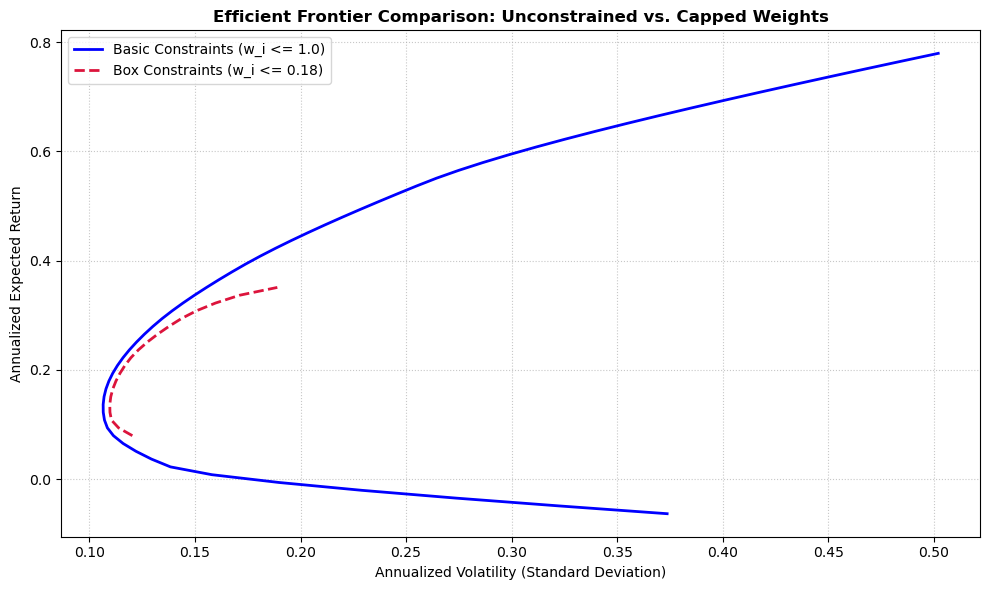

In [108]:
def get_efficient_frontier(mu, C, bounds_max=1.0, n_points=50):
    n_assets = len(mu)
    min_ret = mu.min()
    max_ret = mu.max()
    target_returns = np.linspace(min_ret, max_ret, n_points)

    frontier_volatilities = []
    frontier_returns = []

    for r_target in target_returns:
        def port_variance(w):
            return np.dot(w.T, np.dot(C, w))
        
        constraints = (
            {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
            {'type': 'eq', 'fun': lambda w: np.dot(w, mu) - r_target}
        )
        bounds = tuple((0.0, bounds_max) for _ in range(n_assets))
        init_guess = np.array([1.0 / n_assets] * n_assets)
        
        result = minimize(port_variance, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
        
        if result.success:
            vol = np.sqrt(result.fun)
            frontier_volatilities.append(vol)
            frontier_returns.append(r_target)
            
    return np.array(frontier_volatilities), np.array(frontier_returns)

# Trace efficient frontiers for both constraint sets
vol_basic, ret_basic = get_efficient_frontier(mu_is, C_is, bounds_max=1.0, n_points=60)
vol_capped, ret_capped = get_efficient_frontier(mu_is, C_is, bounds_max=0.18, n_points=60)

# Plotting Code with safe string labels to prevent Matplotlib parser errors
plt.figure(figsize=(10, 6))
plt.plot(vol_basic, ret_basic, color='blue', linewidth=2, label='Basic Constraints (w_i <= 1.0)')
plt.plot(vol_capped, ret_capped, color='crimson', linestyle='--', linewidth=2, label='Box Constraints (w_i <= 0.18)')
plt.title('Efficient Frontier Comparison: Unconstrained vs. Capped Weights', fontsize=12, fontweight='bold')
plt.xlabel('Annualized Volatility (Standard Deviation)', fontsize=10)
plt.ylabel('Annualized Expected Return', fontsize=10)
plt.legend(loc='best', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Step 4: Out-of-Sample Backtesting

Evaluate both portfolios over October 1, 2025 – December 31, 2025, tracking cumulative returns, Sharpe ratios, and maximum drawdown. 

--- Basic Constraints Portfolio (w_i <= 1.0) ---
Cumulative Return:     5.7283%
Annualized Return:     23.4764%
Annualized Volatility: 15.5129%
Sharpe Ratio:          1.2555
Maximum Drawdown:      -3.6291%

--- Box Constraints Portfolio (w_i <= 0.18) ---
Cumulative Return:     1.1775%
Annualized Return:     5.2102%
Annualized Volatility: 10.3450%
Sharpe Ratio:          0.1170
Maximum Drawdown:      -4.1816%



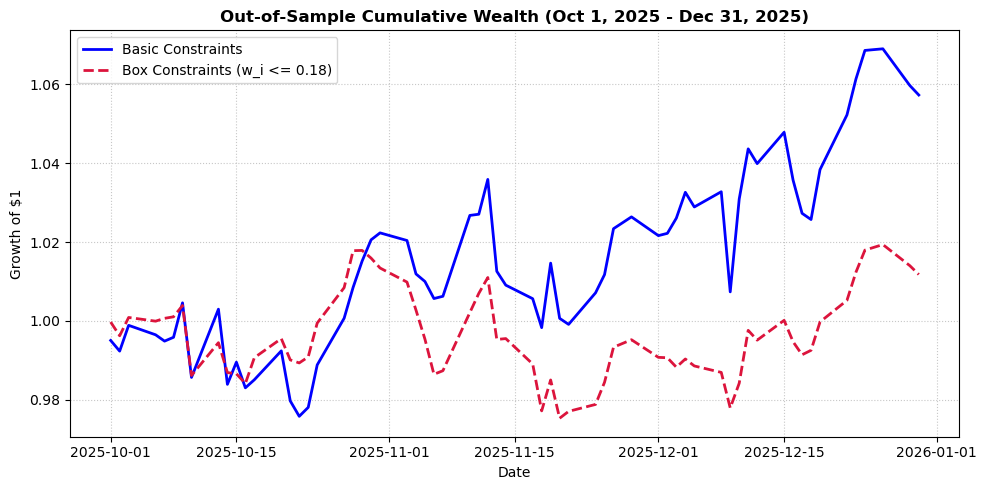

In [110]:
def solve_tangency_portfolio(mu, C, rf=0.04, max_weight=1.0):
    n_assets = len(mu)
    
    def neg_sharpe(w):
        port_return = np.dot(w, mu)
        port_vol = np.sqrt(np.dot(w.T, np.dot(C, w)))
        return -(port_return - rf) / port_vol

    constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
    bounds = tuple((0.0, max_weight) for _ in range(n_assets))
    init_guess = np.array([1.0 / n_assets] * n_assets)

    result = minimize(neg_sharpe, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x

# Step 3: Run optimizations
weights_basic = solve_tangency_portfolio(mu_is, C_is, rf=0.04, max_weight=1.0)
weights_capped = solve_tangency_portfolio(mu_is, C_is, rf=0.04, max_weight=0.18)

# Step 4: Out-of-Sample Backtesting
rf_annual = 0.04
oos_returns_basic = returns_oos.dot(weights_basic)
oos_returns_capped = returns_oos.dot(weights_capped)

def evaluate_portfolio(port_returns, name="Portfolio"):
    cum_wealth = (1 + port_returns).cumprod()
    total_cum_return = cum_wealth.iloc[-1] - 1

    ann_return = port_returns.mean() * 252
    ann_vol = port_returns.std() * np.sqrt(252)
    sharpe = (ann_return - rf_annual) / ann_vol

    peak = cum_wealth.cummax()
    drawdown = (cum_wealth - peak) / peak
    max_dd = drawdown.min()

    print(f"--- {name} ---")
    print(f"Cumulative Return:     {total_cum_return:.4%}")
    print(f"Annualized Return:     {ann_return:.4%}")
    print(f"Annualized Volatility: {ann_vol:.4%}")
    print(f"Sharpe Ratio:          {sharpe:.4f}")
    print(f"Maximum Drawdown:      {max_dd:.4%}\n")

    return cum_wealth

wealth_basic = evaluate_portfolio(oos_returns_basic, "Basic Constraints Portfolio (w_i <= 1.0)")
wealth_capped = evaluate_portfolio(oos_returns_capped, "Box Constraints Portfolio (w_i <= 0.18)")

# Out-of-Sample Cumulative Wealth Plotting
plt.figure(figsize=(10, 5))
plt.plot(wealth_basic.index, wealth_basic, label='Basic Constraints', color='blue', linewidth=2)
plt.plot(wealth_capped.index, wealth_capped, label='Box Constraints (w_i <= 0.18)', color='crimson', linestyle='--', linewidth=2)
plt.title('Out-of-Sample Cumulative Wealth (Oct 1, 2025 - Dec 31, 2025)', fontsize=12, fontweight='bold')
plt.xlabel('Date', fontsize=10)
plt.ylabel('Growth of $1', fontsize=10)
plt.legend(loc='best', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Phase 3: Factor Style Attribution & Regression Analysis (Part 2)

### Step 4: Factor Role Analysis

--- Fama-French 5-Factor Pairwise Correlation Matrix ---
        Mkt-RF     SMB     HML     RMW     CMA
Mkt-RF  1.0000  0.2182 -0.2614 -0.4088 -0.0261
SMB     0.2182  1.0000  0.3821 -0.3950  0.1741
HML    -0.2614  0.3821  1.0000  0.2096  0.1911
RMW    -0.4088 -0.3950  0.2096  1.0000 -0.0157
CMA    -0.0261  0.1741  0.1911 -0.0157  1.0000


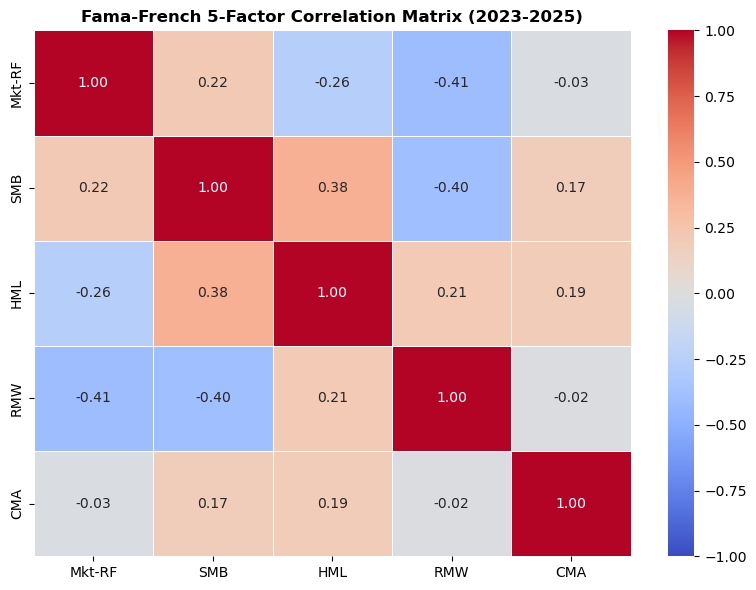

In [111]:
# 1. Download Fama-French 5-Factor Daily Data from Kenneth French's Data Library
url = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_5_Factors_2x3_daily_CSV.zip"
response = requests.get(url)
z = zipfile.ZipFile(io.BytesIO(response.content))

# Extract and read the CSV file from the zip archive within the context manager
csv_filename = z.namelist()[0]
with z.open(csv_filename) as f:
  ff_data = pd.read_csv(f, skiprows=3, index_col=0)

# Clean up column names and index values to remove hidden whitespace
ff_data.columns = ff_data.columns.str.strip()
ff_data.index = pd.to_datetime(
    ff_data.index.astype(str).str.strip(), format="%Y%m%d", errors="coerce"
)

# Drop footer rows (e.g., annual data sections) and completely empty rows
ff_data = ff_data.dropna(how="all")
ff_data = ff_data[ff_data.index.notnull()]

# Keep only the relevant date range matching the sample window
ff_data = ff_data.loc["2023-09-01":"2025-12-31"]
ff_data = ff_data.astype(float) / 100.0

# Select the 5 core factors
factors = ff_data[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]]

# 2. Compute Pairwise Correlation Matrix
corr_matrix = factors.corr()
print("--- Fama-French 5-Factor Pairwise Correlation Matrix ---")
print(corr_matrix.round(4).to_string())

# 3. Visualize Correlation Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
)
plt.title(
    "Fama-French 5-Factor Correlation Matrix (2023-2025)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

### Step 5: Model Estimation

In [115]:
# 1. Prepare Data for Regression
rf_series = ff_data['RF'] if 'RF' in ff_data.columns else 0.04 / 252
port_excess_is = returns_is.dot(weights_basic) - ff_data.loc[returns_is.index, 'RF']

# Independent variables (Factors)
X_is = ff_data.loc[returns_is.index, ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']]
X_is_sm = sm.add_constant(X_is)

# Dependent variable (Portfolio Excess Return)
y_is = port_excess_is

# 2. Ordinary Least Squares (OLS) Estimation
ols_model = sm.OLS(y_is, X_is_sm).fit()
print("================ OLS REGRESSION RESULTS ================")
print(ols_model.summary())

# 3. Robust Linear Model (RLM) Estimation (using Huber norm to downweight outliers)
rlm_model = sm.RLM(y_is, X_is_sm, M=sm.robust.norms.HuberT()).fit()
print("\n================ ROBUST REGRESSION (RLM) RESULTS ================")
print(rlm_model.summary())

================ OLS REGRESSION RESULTS ================
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.722
Model:                            OLS   Adj. R-squared:                  0.719
Method:                 Least Squares   F-statistic:                     266.9
Date:                Sat, 29 Aug 2026   Prob (F-statistic):          2.70e-140
Time:                        12:59:41   Log-Likelihood:                 1922.0
No. Observations:                 520   AIC:                            -3832.
Df Residuals:                     514   BIC:                            -3806.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

### Phase 4: Simulation vs. Hard Optimization (Part 3)

#### •	Subset Selection: Choose 5 representative assets out of the 10-asset universe. 

In [116]:
# 1. Define the 5-asset representative subset
selected_tickers = ['MSFT', 'NVDA', 'JPM', 'JNJ', 'XOM']

# 2. Slice the historical datasets for the subset
subset_adj_close = adj_close[selected_tickers]
subset_returns = returns[selected_tickers]
subset_returns_is = returns_is[selected_tickers]
subset_returns_oos = returns_oos[selected_tickers]

# 3. Recalculate mean returns and covariance matrix for the 5-asset universe
mu_is_subset = subset_returns_is.mean() * annualization_factor
C_is_subset = subset_returns_is.cov() * annualization_factor
print("--- 5-Asset Subset Expected Returns (Annualized) ---")
print(mu_is_subset.round(4).to_string())
print("\n--- 5-Asset Subset Covariance Matrix Preview ---")
print(C_is_subset.round(6).to_string())

--- 5-Asset Subset Expected Returns (Annualized) ---
Ticker
MSFT    0.2525
NVDA    0.7794
JPM     0.4204
JNJ     0.1155
XOM     0.0551

--- 5-Asset Subset Covariance Matrix Preview ---
Ticker      MSFT      NVDA       JPM       JNJ       XOM
Ticker                                                  
MSFT    0.049657  0.061302  0.017553 -0.003639  0.001287
NVDA    0.061302  0.252124  0.032148 -0.023427  0.003041
JPM     0.017553  0.032148  0.053568  0.006132  0.018394
JNJ    -0.003639 -0.023427  0.006132  0.029918  0.006866
XOM     0.001287  0.003041  0.018394  0.006866  0.048865


### Step 7: Basic Simulation Benchmark

In [117]:
# 1. Hard Optimization (Tangency Portfolio for 5-Asset Subset)
def solve_tangency_5asset(mu, C, rf=0.04):
    n = len(mu)
    def neg_sharpe(w):
        ret = np.dot(w, mu)
        vol = np.sqrt(np.dot(w.T, np.dot(C, w)))
        return -(ret - rf) / vol

    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    bounds = tuple((0.0, 1.0) for _ in range(n))
    init = np.array([1.0 / n] * n)

    res = minimize(neg_sharpe, init, method='SLSQP', bounds=bounds, constraints=constraints)
    return res.x

weights_opt = solve_tangency_5asset(mu_is_subset, C_is_subset, rf=0.04)
df_opt = pd.DataFrame({'Asset': selected_tickers, 'Optimal Weight': weights_opt})

# 2. Monte Carlo Simulation Convergence Analysis
def run_monte_carlo(mu, C, rf=0.04, n_simulations=50000):
    n_assets = len(mu)
    results_weights = np.zeros((n_simulations, n_assets))
    results_metrics = np.zeros((3, n_simulations)) # ret, vol, sharpe

    np.random.seed(42)
    for i in range(n_simulations):
        w = np.random.random(n_assets)
        w /= np.sum(w)
        results_weights[i, :] = w
        
        ret = np.dot(w, mu)
        vol = np.sqrt(np.dot(w.T, np.dot(C, w)))
        sharpe = (ret - rf) / vol
        
        results_metrics[0, i] = ret
        results_metrics[1, i] = vol
        results_metrics[2, i] = sharpe
        
    max_idx = np.argmax(results_metrics[2])
    return results_weights[max_idx], results_metrics[:, max_idx]

# Test convergence across sample sizes
sample_sizes = [1000, 10000, 50000, 100000]
convergence_records = []
for n_sim in sample_sizes:
    best_w, best_metrics = run_monte_carlo(mu_is_subset, C_is_subset, rf=0.04, n_simulations=n_sim)
    convergence_records.append({
        'Simulations': n_sim,
        'Max Sharpe': round(best_metrics[2], 4),
        **{selected_tickers[j]: round(best_w[j], 4) for j in range(len(selected_tickers))}
    })

df_convergence = pd.DataFrame(convergence_records)
print("--- Hard Optimization Tangency Weights ---")
print(df_opt.to_string(index=False))
print("\n--- Monte Carlo Convergence Across Sample Sizes ---")
print(df_convergence.to_string(index=False))

--- Hard Optimization Tangency Weights ---
Asset  Optimal Weight
 MSFT    0.000000e+00
 NVDA    2.314078e-01
  JPM    4.568110e-01
  JNJ    3.117812e-01
  XOM    8.807098e-17

--- Monte Carlo Convergence Across Sample Sizes ---
 Simulations  Max Sharpe   MSFT   NVDA    JPM    JNJ    XOM
        1000      1.9967 0.0329 0.2708 0.4261 0.2427 0.0275
       10000      2.0301 0.0099 0.2173 0.4591 0.3081 0.0056
       50000      2.0301 0.0099 0.2173 0.4591 0.3081 0.0056
      100000      2.0301 0.0099 0.2173 0.4591 0.3081 0.0056


### Step 8: Constrained Simulation (Introduce 30% individual asset cap constraints) 

In [83]:
# 1. Analytical Optimization with 30% Individual Cap
def solve_tangency_capped_5asset(mu, C, rf=0.04, max_weight=0.30):
    n = len(mu)
    def neg_sharpe(w):
        ret = np.dot(w, mu)
        vol = np.sqrt(np.dot(w.T, np.dot(C, w)))
        return -(ret - rf) / vol

    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    bounds = tuple((0.0, max_weight) for _ in range(n))
    init = np.array([1.0 / n] * n)
    
    res = minimize(neg_sharpe, init, method='SLSQP', bounds=bounds, constraints=constraints)
    return res.x

weights_opt_capped = solve_tangency_capped_5asset(mu_is_subset, C_is_subset, rf=0.04, max_weight=0.30)
df_opt_capped = pd.DataFrame({'Asset': selected_tickers, 'Capped Optimal Weight': weights_opt_capped})

# 2. Constrained Monte Carlo Simulation with Rejection Sampling
def run_monte_carlo_bounded(mu, C, rf=0.04, max_weight=0.30, n_simulations=50000):
    n_assets = len(mu)
    results_metrics = []
    results_weights = []
    
    np.random.seed(42)
    valid_count = 0
    while valid_count < n_simulations:
        batch_size = (n_simulations - valid_count) * 3 # generate in batches to ensure efficiency
        w_batch = np.random.random((batch_size, n_assets))
        w_batch /= w_batch.sum(axis=1, keepdims=True)
        
        # Filter rows where all weights <= max_weight
        mask = np.all(w_batch <= max_weight, axis=1)
        valid_w = w_batch[mask]
        
        for w in valid_w:
            ret = np.dot(w, mu)
            vol = np.sqrt(np.dot(w.T, np.dot(C, w)))
            sharpe = (ret - rf) / vol
            results_metrics.append((ret, vol, sharpe))
            results_weights.append(w)
            valid_count += 1
            if valid_count >= n_simulations:
                break
                
    metrics_arr = np.array(results_metrics)
    weights_arr = np.array(results_weights)
    max_idx = np.argmax(metrics_arr[:, 2])
    return weights_arr[max_idx], metrics_arr[max_idx]

# Test convergence across sample sizes under constraints
sample_sizes = [1000, 10000, 50000, 100000]
constrained_records = []

for n_sim in sample_sizes:
    best_w, best_metrics = run_monte_carlo_bounded(mu_is_subset, C_is_subset, rf=0.04, max_weight=0.30, n_simulations=n_sim)
    constrained_records.append({
        'Simulations': n_sim,
        'Max Sharpe': round(best_metrics[2], 4),
        **{selected_tickers[j]: round(best_w[j], 4) for j in range(len(selected_tickers))}
    })

df_constrained_conv = pd.DataFrame(constrained_records)

print("--- Analytical Capped Optimization Weights (max = 30%) ---")
print(df_opt_capped.to_string(index=False))
print("\n--- Constrained Monte Carlo Convergence ---")
print(df_constrained_conv.to_string(index=False))

--- Analytical Capped Optimization Weights (max = 30%) ---
Asset  Capped Optimal Weight
 MSFT               0.142105
 NVDA               0.257148
  JPM               0.300000
  JNJ               0.300000
  XOM               0.000746

--- Constrained Monte Carlo Convergence ---
 Simulations  Max Sharpe   MSFT   NVDA    JPM    JNJ    XOM
        1000      1.9344 0.1545 0.2652 0.2933 0.2732 0.0138
       10000      1.9411 0.1341 0.2412 0.2905 0.2932 0.0411
       50000      1.9509 0.1483 0.2467 0.2975 0.2950 0.0125
      100000      1.9509 0.1483 0.2467 0.2975 0.2950 0.0125


### Phase 5: Black-Litterman Asset Allocation (Part 4)

In [118]:
# 1. Define Expanded Ticker Universe (10 equities + SPY as 11th asset)
tickers_11 = ['AMZN', 'MSFT', 'JPM', 'JNJ', 'V', 'UNH', 'PG', 'HD', 'XOM', 'NVDA', 'SPY']
start_date = '2023-09-01'
end_date = '2025-12-31'

# Download data for all 11 assets
data_11 = yf.download(tickers_11, start=start_date, end=end_date, interval='1d', auto_adjust=False)
adj_close_11 = data_11['Adj Close']

# 2. Return Calculation & In-Sample Slicing
returns_11 = adj_close_11.pct_change().dropna()
returns_11_is = returns_11.loc['2023-09-01':'2025-09-30']

# Annualized parameters for 11-asset universe
annualization_factor = 252
mu_11_is = returns_11_is.mean() * annualization_factor
C_11_is = returns_11_is.cov() * annualization_factor

print("--- Augmented 11x11 Covariance Matrix Dimensions ---")
print(C_11_is.shape)

print("\n--- Annualized Expected Returns (11-Asset Universe Preview) ---")
print(mu_11_is.round(4).to_string())

[*********************100%***********************]  11 of 11 completed

--- Augmented 11x11 Covariance Matrix Dimensions ---
(11, 11)

--- Annualized Expected Returns (11-Asset Universe Preview) ---
Ticker
AMZN    0.2728
HD      0.1415
JNJ     0.1155
JPM     0.4204
MSFT    0.2525
NVDA    0.7794
PG      0.0357
SPY     0.2160
UNH    -0.0632
V       0.1803
XOM     0.0551


### Step 9b-d: Parameter Setup & Views

In [119]:
# 1. Parameter Setup
T = len(returns_11_is)
tau = 1.0 / T
delta = 2.5  

# Market capitalization or proxy weights 
n_assets = len(tickers_11)
w_mkt = np.ones(n_assets) / n_assets

# Implied Equilibrium Returns (Pi)
Pi = delta * np.dot(C_11_is, w_mkt)

# 2. View Specification (K = 2 views, N = 11 assets)
P = np.zeros((2, n_assets))
Q = np.zeros(2)

# View 1: NVDA outperforms MSFT by +3% (0.03) annualized
P[0, 9] = 1.0   
P[0, 1] = -1.0  
Q[0] = 0.03

# View 2: XOM absolute expected return of +8.5% (0.085) annualized
P[1, 8] = 1.0   
Q[1] = 0.085

# View uncertainty matrix Omega (Idzorek diagonal method)
tau_C = tau * C_11_is
Omega = np.diag(np.diag(np.dot(P, np.dot(tau_C, P.T))))

# 3. Black-Litterman Posterior Derivation
inv_tau_C = np.linalg.inv(tau_C)
inv_Omega = np.linalg.inv(Omega)

# Posterior Covariance Matrix (Sigma_BL)
bracket_inv = np.linalg.inv(inv_tau_C + np.dot(P.T, np.dot(inv_Omega, P)))
Sigma_BL = C_11_is + bracket_inv

# Posterior Expected Returns (mu_BL)
term_pi_q = np.dot(inv_tau_C, Pi) + np.dot(P.T, np.dot(inv_Omega, Q))
mu_BL = np.dot(Sigma_BL, term_pi_q)

# Compile Results DataFrame
df_bl = pd.DataFrame({
    'Asset': tickers_11,
    'Prior Equilibrium (Pi)': Pi,
    'Posterior Expected Return (mu_BL)': mu_BL
})

print("--- Black-Litterman Prior vs Posterior Expected Returns ---")
print(df_bl.round(4).to_string(index=False))

--- Black-Litterman Prior vs Posterior Expected Returns ---
Asset  Prior Equilibrium (Pi)  Posterior Expected Return (mu_BL)
 AMZN                  0.0754                            40.0284
 MSFT                  0.0418                            14.6780
  JPM                  0.0110                             8.4684
  JNJ                  0.0513                            30.6067
    V                  0.0511                            27.6274
  UNH                  0.1105                            56.4307
   PG                  0.0134                             8.7745
   HD                  0.0515                            28.4443
  XOM                  0.0405                            66.5955
 NVDA                  0.0441                            32.8636
  SPY                  0.0278                            14.9922


### Step 9e: Comparative Evaluation

In [120]:
# 1. Define Black-Litterman Tangency Portfolio Optimizer 
def solve_bl_tangency(mu_bl, sigma_bl, rf=0.04):
    n_assets = len(mu_bl)
    def neg_sharpe_bl(w):
        ret = np.dot(w, mu_bl)
        vol = np.sqrt(np.dot(w.T, np.dot(sigma_bl, w)))
        return -(ret - rf) / vol

    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    bounds = tuple((0.0, 1.0) for _ in range(n_assets))
    init = np.array([1.0 / n_assets] * n_assets)
    
    res = minimize(neg_sharpe_bl, init, method='SLSQP', bounds=bounds, constraints=constraints)
    return res.x

# 2. Compute Weights
weights_bl = solve_bl_tangency(mu_BL, Sigma_BL, rf=0.04)

# Compare with Prior (Traditional Optimization Weights)
def solve_prior_tangency(mu, C, rf=0.04):
    n_assets = len(mu)
    def neg_sharpe(w):
        ret = np.dot(w, mu)
        vol = np.sqrt(np.dot(w.T, np.dot(C, w)))
        return -(ret - rf) / vol

    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    bounds = tuple((0.0, 1.0) for _ in range(n_assets))
    init = np.array([1.0 / n_assets] * n_assets)
    res = minimize(neg_sharpe, init, method='SLSQP', bounds=bounds, constraints=constraints)
    return res.x

weights_prior = solve_prior_tangency(mu_11_is, C_11_is, rf=0.04)

# Compile Comparison DataFrame
df_comparison = pd.DataFrame({
    'Asset': tickers_11,
    'Traditional Prior Weight': weights_prior,
    'Black-Litterman Weight': weights_bl
})

print("--- 11-Asset Portfolio Weight Comparison ---")
print(df_comparison.round(4).to_string(index=False))

--- 11-Asset Portfolio Weight Comparison ---
Asset  Traditional Prior Weight  Black-Litterman Weight
 AMZN                    0.0000                  0.0657
 MSFT                    0.0000                  0.0000
  JPM                    0.3120                  0.0522
  JNJ                    0.4566                  0.0756
    V                    0.0000                  0.0843
  UNH                    0.2314                  0.0752
   PG                    0.0000                  0.0568
   HD                    0.0000                  0.0000
  XOM                    0.0000                  0.2664
 NVDA                    0.0000                  0.2532
  SPY                    0.0000                  0.0704
